Class distribution:
shape: (3, 3)
┌─────────────────┬──────────┬────────────┐
│ PREDICTED_CLASS ┆ count    ┆ percentage │
│ ---             ┆ ---      ┆ ---        │
│ str             ┆ u32      ┆ f64        │
╞═════════════════╪══════════╪════════════╡
│ STAR            ┆ 6861079  ┆ 6.810363   │
│ QSO             ┆ 1560090  ┆ 1.548558   │
│ GALAXY          ┆ 92323516 ┆ 91.641079  │
└─────────────────┴──────────┴────────────┘


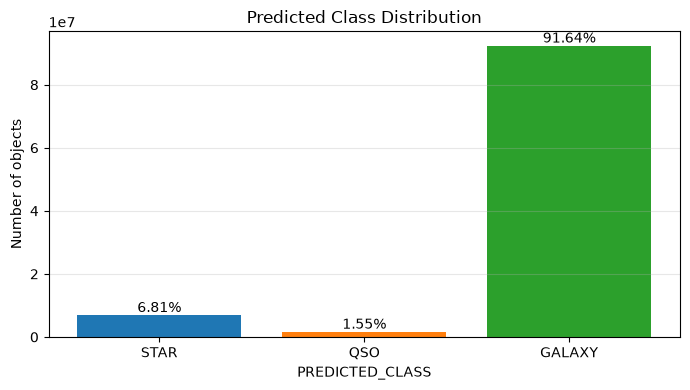

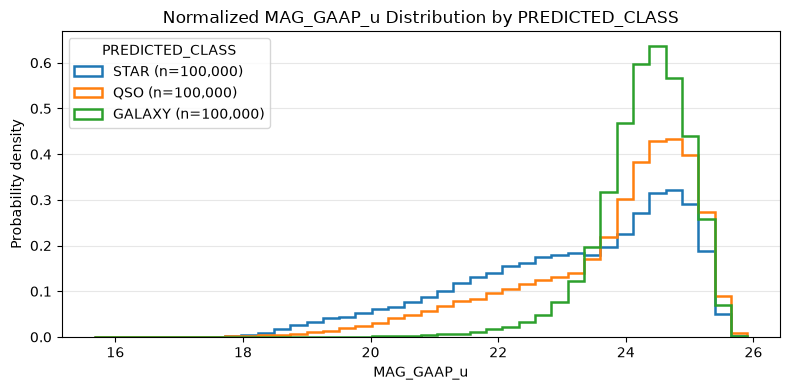

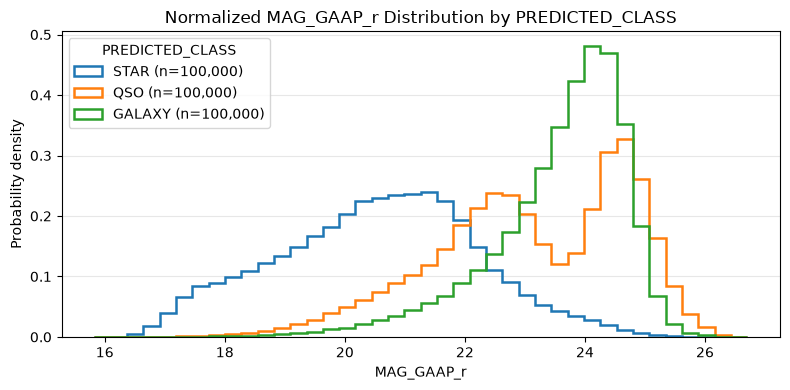

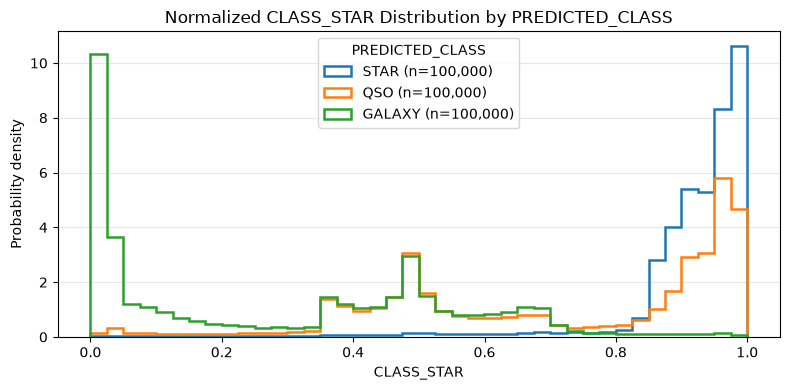

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import polars as pl

# 1. Konfiguracja i ścieżki
data_path = "../data/inference/KiDS_DR5_WCScut_columns_SPECTYPE.csv"
target = "PREDICTED_CLASS"
class_order = ["STAR", "QSO", "GALAXY"]
class_colors = {"STAR": "tab:blue", "QSO": "tab:orange", "GALAXY": "tab:green"}
selected_features = ["MAG_GAAP_u", "MAG_GAAP_r", "CLASS_STAR"]#, "J/Ks", "u/r"]

max_per_class = 100_000
sample_seed = 42
missing_values = [-99.0, 99.0]

# Inicjalizacja LazyFrame - nie ładuje pliku do RAMu
lazy_df = pl.scan_csv(data_path, infer_schema_length=1_000)

# 2. OBLICZENIE PROCENTÓW KLAS (Bardzo bezpieczne dla RAMu)
class_stats = (
    lazy_df.filter(pl.col(target).is_in(class_order))
    .group_by(target)
    .len(name="count")
    .with_columns(
        (pl.col("count") / pl.col("count").sum() * 100).alias("percentage")
    )
    .collect()  # Pobiera tylko małą tabelkę wynikową (3 wiersze)
)

# Sortowanie i uzupełnianie braków zgodnie z pierwotnym kodem
class_stats = (
    pl.DataFrame({target: class_order})
    .join(class_stats, on=target, how="left")
    .with_columns(
        pl.col("count").fill_null(0),
        pl.col("percentage").fill_null(0.0),
    )
)

print("Class distribution:")
print(class_stats)

# Wykres rozkładu klas
fig, ax = plt.subplots(figsize=(7, 4))
counts = class_stats["count"].to_list()
percentages = class_stats["percentage"].to_list()
ax.bar(class_order, counts, color=[class_colors[name] for name in class_order])
for idx, (count, percentage) in enumerate(zip(counts, percentages)):
    ax.text(idx, count, f"{percentage:.2f}%", ha="center", va="bottom")
ax.set_title("Predicted Class Distribution")
ax.set_xlabel(target)
ax.set_ylabel("Number of objects")
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
plt.show()

# 3. PRÓBKOWANIE STRUMIENIOWE (Zabezpieczenie przed brakiem RAMu)
# Budujemy jedno zapytanie Lazy, które ograniczy pamięć przed zrzuceniem do NumPy
sampled_dfs = []

for class_name in class_order:
    # Filtrujemy nieprawidłowe wartości wewnątrz silnika Lazy
    class_lazy = lazy_df.filter(
        (pl.col(target) == class_name)
        & pl.all_horizontal(pl.col(selected_features).is_not_null())
        & ~pl.any_horizontal(pl.col(selected_features).is_in(missing_values))
    ).select([target] + selected_features)
    
    # Próbkowanie o stałym zużyciu pamięci za pomocą sortowania z losowym ziarnem
    # i ucięcia za pomocą .head()
    sampled_class_lazy = (
        class_lazy
        .with_columns(pl.lit(sample_seed).alias("seed"))
        .with_columns(pl.col("seed").shuffle(seed=sample_seed))
        .sort("seed")
        .drop("seed")
        .head(max_per_class)
    )
    
    sampled_dfs.append(sampled_class_lazy)

# Łączymy zapytania i wykonujemy JEDNO pobranie przefiltrowanych, małych danych (max 75k wierszy)
data_subset = pl.concat(sampled_dfs).collect()

# 4. GENEROWANIE HISTOGRAMÓW DLA WYBRANYCH CECH
for feature in selected_features:
    if feature not in data_subset.columns:
        print(f"Feature {feature} not found in CSV.")
        continue
        
    per_class_values = []
    active_classes = []
    
    for class_name in class_order:
        values = (
            data_subset.filter(pl.col(target) == class_name)
            .get_column(feature)
            .to_numpy()
        )
        if len(values) > 0:
            per_class_values.append(values)
            active_classes.append(class_name)
            
    if not per_class_values:
        print(f"Skipping {feature}: no valid values")
        continue

    # Definiowanie koszyków (bins)
    all_values = np.concatenate(per_class_values)
    feature_min, feature_max = float(np.min(all_values)), float(np.max(all_values))
    if feature_min == feature_max:
        bin_edges = np.linspace(feature_min - 0.5, feature_max + 0.5, 21)
    else:
        bin_edges = np.linspace(feature_min, feature_max, 41)

    # Rysowanie histogramu
    fig, ax = plt.subplots(figsize=(8, 4))
    for class_name, values in zip(active_classes, per_class_values):
        ax.hist(
            values,
            bins=bin_edges,
            density=True,
            histtype="step",
            linewidth=1.8,
            label=f"{class_name} (n={len(values):,})",
            color=class_colors[class_name],
        )
    ax.set_title(f"Normalized {feature} Distribution by {target}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Probability density")
    ax.legend(title=target)
    ax.grid(axis="y", alpha=0.3)
    fig.tight_layout()
    plt.show()
